In [1]:
%pip install -U langgraph langchain langchain-core langchain-openrouter pydantic langchain-openai

Defaulting to user installation because normal site-packages is not writeable
  Using cached typing_inspection-0.4.4-py3-none-any.whl.metadata (2.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 687.8 kB/s eta 0:00:00a 0:00:01
  Attempting uninstall: orjson
    Found existing installation: orjson 3.10.18
    Uninstalling orjson-3.10.18:
      Successfully uninstalled orjson-3.10.18
  Attempting uninstall: jiter
    Found existing installation: jiter 0.13.0
    Uninstalling jiter-0.13.0:
      Successfully uninstalled jiter-0.13.0
  Attempting uninstall: openai
    Found existing installation: openai 2.18.0
    Uninstalling openai-2.18.0:
      Successfully uninstalled openai-2.18.0━━━━━━━━━━━━━━━━━━━━━━ 2/9 [openai]
  Attempting uninstall: langgraph-sdk━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/9 [openai]
    Found existing installation: langgraph-sdk 0.3.4━━━━━━━━━━ 2/9 [openai]
    Uninstalling langgraph-sdk-0.3.4:━━━━━━━━━━━━━━━━━━━━━━━━━ 2/9 [openai]
      Successfully uninstalled

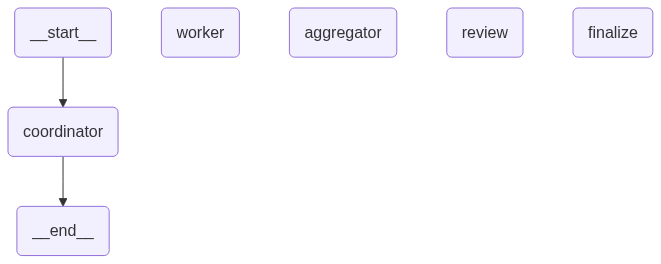


Coordinator selected:
  research: Investigate current best practices and real-world patterns for scaling RAG systems to one million+ document chunks. Cover: vector database options (e.g., Pinecone, Weaviate, Milvus, Qdrant, pgvector) and their scaling characteristics, embedding model selection and dimensionality trade-offs, chunking strategies (size, overlap, semantic vs fixed), indexing algorithms (HNSW, IVF, product quantization) and their memory/latency/recall profiles, and hybrid search (dense + sparse/BM25) with reranking. Gather supporting evidence on throughput, latency, and recall benchmarks at this scale.
  coding: Design the end-to-end technical architecture for a RAG application handling one million document chunks. Specify: the ingestion pipeline (document loading, chunking, embedding generation, batch upserts), the vector store configuration and index parameters, the retrieval layer (dense retrieval + hybrid search + reranking), the generation layer with prompt assembly a

In [ ]:

import operator
from typing import Annotated, Literal
from typing_extensions import TypedDict

from pydantic import BaseModel, Field

from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, SystemMessage

from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

from IPython.display import Image, display


# ============================================================
# 1. LLM
# ============================================================

llm = ChatOpenAI(
    model="anthropic--claude-4.8-opus",
    base_url="http://localhost:6655/litellm/v1",
    api_key="<HAI-API-KEY>"
)


# ============================================================
# 2. STRUCTURED OUTPUT SCHEMAS
# ============================================================

class AgentTask(BaseModel):
    agent: Literal["research", "coding", "analysis"]
    task: str = Field(description="The specific task for this agent")


class AgentPlan(BaseModel):
    tasks: list[AgentTask] = Field(
        min_length=1,
        max_length=3,
        description="Select only the agents needed for the request"
    )


class FinalAnswer(BaseModel):
    answer: str
    review_status: Literal["approved", "needs_revision"]
    issues: list[str]


# Coordinator and final response use structured output.
planner_llm = llm.with_structured_output(AgentPlan,method="function_calling")
final_llm = llm.with_structured_output(FinalAnswer,method="function_calling")


# ============================================================
# 3. TOOLS
# Replace demo implementations with real tools as needed.
# ============================================================

@tool
def search_knowledge_base(query: str) -> str:
    """Search a knowledge base for relevant information."""
    return (
        f"Demo knowledge-base search for '{query}'. "
        "No real document store is connected."
    )


@tool
def inspect_code_requirements(requirements: str) -> str:
    """Identify implementation concerns and edge cases."""
    return (
        f"For '{requirements}', consider input validation, "
        "error handling, modular design, and automated tests."
    )


@tool
def calculate_word_count(text: str) -> str:
    """Calculate the number of words in a text."""
    return f"Word count: {len(text.split())}"


# ============================================================
# 4. REACT AGENTS USING create_agent()
# ============================================================

research_agent = create_agent(
    model=llm,
    tools=[search_knowledge_base],
    system_prompt=(
        "You are a research specialist. Investigate the assigned task. "
        "Use tools when helpful. Distinguish evidence from assumptions."
    ),
)

coding_agent = create_agent(
    model=llm,
    tools=[inspect_code_requirements],
    system_prompt=(
        "You are a coding specialist. Design practical technical solutions. "
        "Consider architecture, error handling, and edge cases."
    ),
)

analysis_agent = create_agent(
    model=llm,
    tools=[calculate_word_count],
    system_prompt=(
        "You are an analysis specialist. Examine trade-offs, "
        "identify risks, and provide actionable recommendations."
    ),
)

review_agent = create_agent(
    model=llm,
    tools=[search_knowledge_base, inspect_code_requirements],
    system_prompt=(
        "You are an independent review specialist. Check the draft for "
        "errors, missing requirements, unsupported claims, and contradictions. "
        "Provide specific corrections where possible."
    ),
)

AGENTS = {
    "research": research_agent,
    "coding": coding_agent,
    "analysis": analysis_agent,
}


# ============================================================
# 5. GRAPH STATE
# ============================================================

class State(TypedDict):
    user_request: str
    plan: list[AgentTask]
    worker_results: Annotated[list[dict], operator.add]
    draft: str
    review: str
    final_answer: dict


class WorkerInput(TypedDict):
    agent: Literal["research", "coding", "analysis"]
    task: str
    user_request: str


# ============================================================
# 6. COORDINATOR
# LLM decides which agents to invoke and how many.
# ============================================================

def coordinator(state: State):
    plan = planner_llm.invoke([
        SystemMessage(content="""
You coordinate three specialist agents:

- research: investigate information and supporting evidence
- coding: design technical solutions
- analysis: evaluate approaches and trade-offs

Select only the agents needed for the request.
Select one, two, or all three agents.
Assign each selected agent a specific, non-redundant task.
Do not select the review agent; it always runs afterward.
"""),
        HumanMessage(content=state["user_request"]),
    ])

    # Avoid dispatching the same specialist multiple times.
    unique_tasks = []
    seen_agents = set()

    for task in plan.tasks:
        if task.agent not in seen_agents:
            unique_tasks.append(task)
            seen_agents.add(task.agent)

    if not unique_tasks:
        raise ValueError("The coordinator selected no agents.")

    print("\nCoordinator selected:")
    for task in unique_tasks:
        print(f"  {task.agent}: {task.task}")

    return {"plan": unique_tasks}


# ============================================================
# 7. DYNAMIC FAN-OUT
# One Send per selected specialist.
# ============================================================

def dispatch(state: State):
    return [
        Send(
            "worker",
            {
                "agent": task.agent,
                "task": task.task,
                "user_request": state["user_request"],
            },
        )
        for task in state["plan"]
    ]


# ============================================================
# 8. WORKER
# Each parallel invocation receives its own WorkerInput.
# ============================================================

def worker(state: WorkerInput):
    agent_name = state["agent"]
    agent_task = state["task"]

    agent = AGENTS[agent_name]

    response = agent.invoke({
        "messages": [
            HumanMessage(content=(
                f"Original user request:\n{state['user_request']}\n\n"
                f"Your assigned task:\n{agent_task}\n\n"
                "Complete your task and return your findings."
            ))
        ]
    })

    result = response["messages"][-1].content

    # Each worker returns one result.
    # operator.add merges parallel results into the shared state.
    return {
        "worker_results": [{
            "agent": agent_name,
            "task": agent_task,
            "result": result,
        }]
    }


# ============================================================
# 9. AGGREGATOR / FAN-IN
# Runs after the dispatched workers finish.
# ============================================================

def aggregator(state: State):
    sections = []

    for item in state["worker_results"]:
        sections.append(
            f"Agent: {item['agent']}\n"
            f"Task: {item['task']}\n"
            f"Result:\n{item['result']}"
        )

    draft = "\n\n---\n\n".join(sections)

    print("\nAggregator received all worker results.")

    return {"draft": draft}


# ============================================================
# 10. REVIEW AGENT
# Always runs after aggregation.
# ============================================================

def review(state: State):
    response = review_agent.invoke({
        "messages": [
            HumanMessage(content=(
                f"Original request:\n{state['user_request']}\n\n"
                f"Combined draft:\n{state['draft']}\n\n"
                "Review the draft for correctness, missing requirements, "
                "unsupported assumptions, and contradictions. "
                "Provide concrete findings and suggested corrections."
            ))
        ]
    })

    review_text = response["messages"][-1].content

    print("\nReview agent completed.")

    return {"review": review_text}


# ============================================================
# 11. FINAL STRUCTURED ANSWER
# ============================================================

def finalize(state: State):
    response = final_llm.invoke([
        SystemMessage(content="""
Produce the final answer using the specialist findings and review.
Address the review findings where possible.
Do not claim that something was verified without supporting evidence.
Use approved only when no material issues remain.
Otherwise use needs_revision and explain the remaining issues.
"""),
        HumanMessage(content=(
            f"User request:\n{state['user_request']}\n\n"
            f"Specialist findings:\n{state['draft']}\n\n"
            f"Review findings:\n{state['review']}"
        )),
    ])

    return {"final_answer": response.model_dump()}


# ============================================================
# 12. BUILD THE GRAPH
# ============================================================

builder = StateGraph(State)

builder.add_node("coordinator", coordinator)
builder.add_node("worker", worker)
builder.add_node("aggregator", aggregator)
builder.add_node("review", review)
builder.add_node("finalize", finalize)

builder.add_edge(START, "coordinator")

# Dynamic fan-out: one or more worker executions.
builder.add_conditional_edges("coordinator", dispatch)

# Fan-in: wait for all worker executions in this dispatch batch.
builder.add_edge("worker", "aggregator")

builder.add_edge("aggregator", "review")
builder.add_edge("review", "finalize")
builder.add_edge("finalize", END)

graph = builder.compile()


# ============================================================
# 13. GENERATE AND DISPLAY GRAPH IMAGE
# Run this in Jupyter Notebook or Google Colab.
# ============================================================

try:
    graph_image = graph.get_graph().draw_mermaid_png()
    display(Image(graph_image))
except Exception as exc:
    print("Could not render the PNG:", exc)
    print("Mermaid graph source:")
    print(graph.get_graph().draw_mermaid())


# ============================================================
# 14. EXECUTE THE GRAPH
# ============================================================

result = graph.invoke({
    "user_request": (
        "Design a scalable RAG application that can handle "
        "one million document chunks."
    ),
    "plan": [],
    "worker_results": [],
    "draft": "",
    "review": "",
    "final_answer": {},
})


# ============================================================
# 15. DISPLAY FINAL RESULT
# ============================================================

print("\nFINAL STRUCTURED ANSWER")

final_answer = FinalAnswer.model_validate(
    result["final_answer"]
)

print(final_answer.model_dump_json(indent=2))


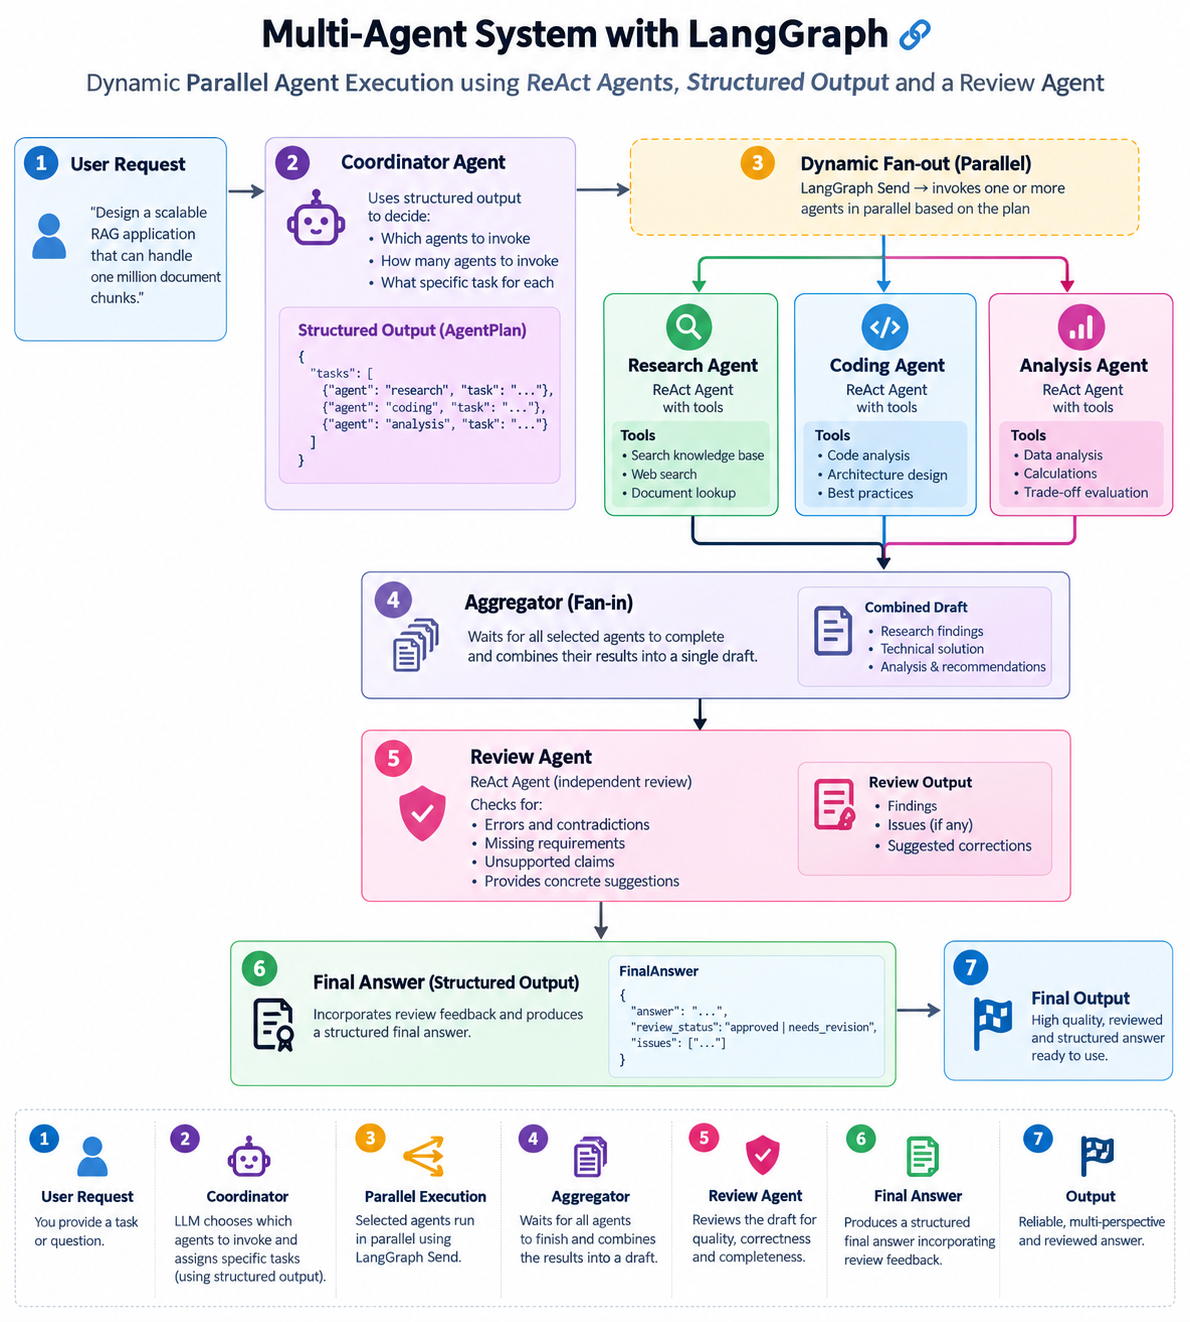

In [3]:
from IPython.display import Image, display

display(Image(filename="LangGraph Multi-Agent Workflow Infographic.png"))